In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

In [4]:
company = pd.read_csv('data/project_sql_result_01.csv')
dropoff = pd.read_csv('data/project_sql_result_04.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'data/project_sql_result_01.csv'

## Dataframe company

 #### Imprimindo as informações gerais do DataFrame 

In [ ]:
company.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB


#### Imprimindo as estatísticas descritivas 

In [ ]:
company.describe()

,trips_amount
count,64.000000
mean,2145.484375
std,3812.310186
min,2.000000
25%,20.750000
50%,178.500000
75%,2106.500000
max,19558.000000


#### Imprimindo as primeiras 5 linhas 

In [ ]:
company.head()

,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasing,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


#### Verificando se existe linhas duplicadas

In [ ]:
company.duplicated().sum()

0

#### Conclusões
Após essa primeira análise dos dados do dataframe company, podemos observar que os tipos de dados estão corretos. A coluna company_name está no tipo object, o que é esperado, pois armazena os nomes das companhias, ou seja, dados do tipo string. Já a coluna trips_amount está no tipo int, o que também está correto por representar a quantidade de viagens, um valor numérico inteiro. Além disso, não foram encontrados valores ausentes nem linhas duplicadas no conjunto de dados. Por fim, a análise estatística descritiva permite obter uma visão geral da distribuição dos dados, auxiliando na compreensão das principais características do dataframe.

## Dataframe dropoff

#### Imprimindo as informações gerais do DataFrame

In [ ]:
dropoff.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB


#### Imprimindo as estatísticas descritivas 

In [ ]:
dropoff.describe()

,average_trips
count,94.000000
mean,599.953728
std,1714.591098
min,1.800000
25%,14.266667
50%,52.016667
75%,298.858333
max,10727.466667


#### Imprimindo as primeiras linhas 

In [ ]:
dropoff.head()

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000


#### Verificando se existe linhas duplicadas 

In [ ]:
dropoff.duplicated().sum()

0

#### Conclusão 
Após essa primeira análise dos dados do dataframe dropoff, podemos observar que os tipos dos dados estão corretos. A coluna dropoff_location_name está no tipo object, o que é adequado por armazenar os nomes dos bairros (strings). Já a coluna average_trips está no tipo float, pois representa a média de viagens, que pode conter valores decimais. Além disso, não há valores ausentes nas colunas, e a análise estatística descritiva mostra que a distribuição das médias de viagens é bastante dispersa, com poucos bairros concentrando um número muito elevado de viagens em comparação com os demais.

## Top 10 principais bairros por destino 

In [ ]:
top10 = dropoff.sort_values(by= 'average_trips', ascending=False).head(10)
top10

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667


### Empresas de táxi e número de corridas

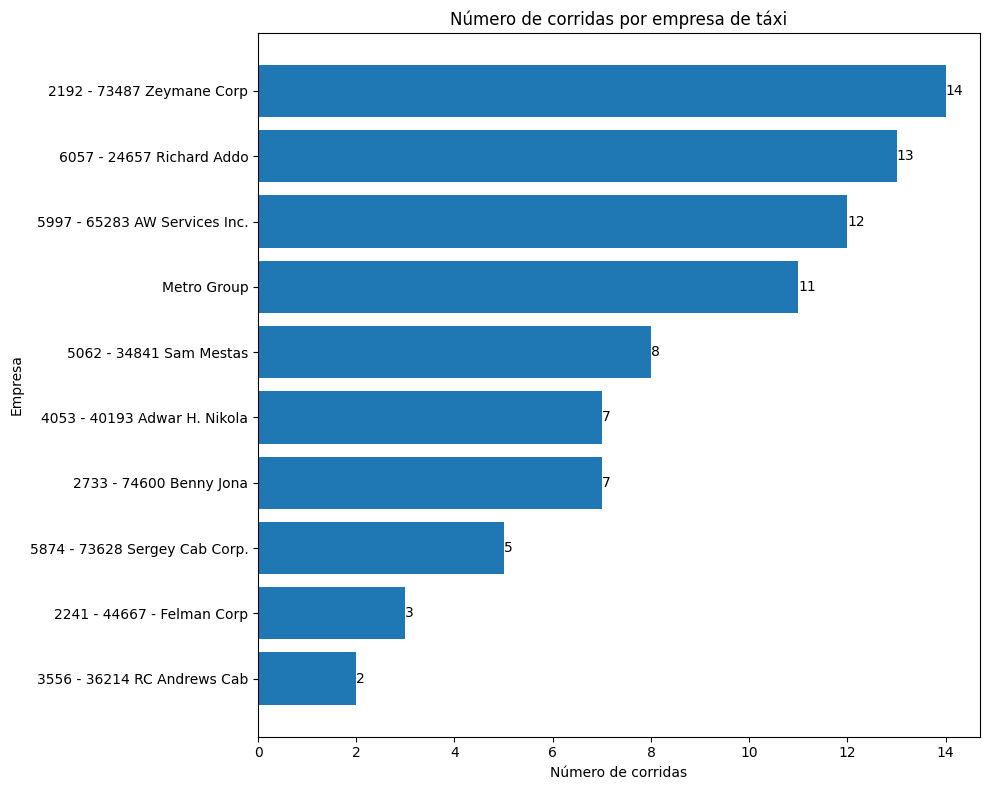

In [ ]:
company_sorted = company.sort_values(by='trips_amount',ascending=True).head(10)

plt.figure(figsize=(10, 8))

plt.barh( company_sorted['company_name'], company_sorted['trips_amount'])

plt.title('Número de corridas por empresa de táxi')
plt.xlabel('Número de corridas')
plt.ylabel('Empresa')


for index, value in enumerate(company_sorted['trips_amount']):
    plt.text(
        value,
        index,
        str(value),
        va='center'
    )

plt.tight_layout()
plt.show()

#### Conclusão
A análise do gráfico de empresas de táxi e número de corridas mostra que existe uma grande diferença na quantidade de viagens realizadas entre as companhias. Algumas empresas concentram uma parcela significativa das corridas, enquanto outras apresentam um volume consideravelmente menor. Isso indica que o mercado de táxis possui uma distribuição desigual de demanda, com poucas empresas sendo responsáveis pela maior parte dos deslocamentos realizados no período analisado.

#### Top 10 bairros por número de corridas

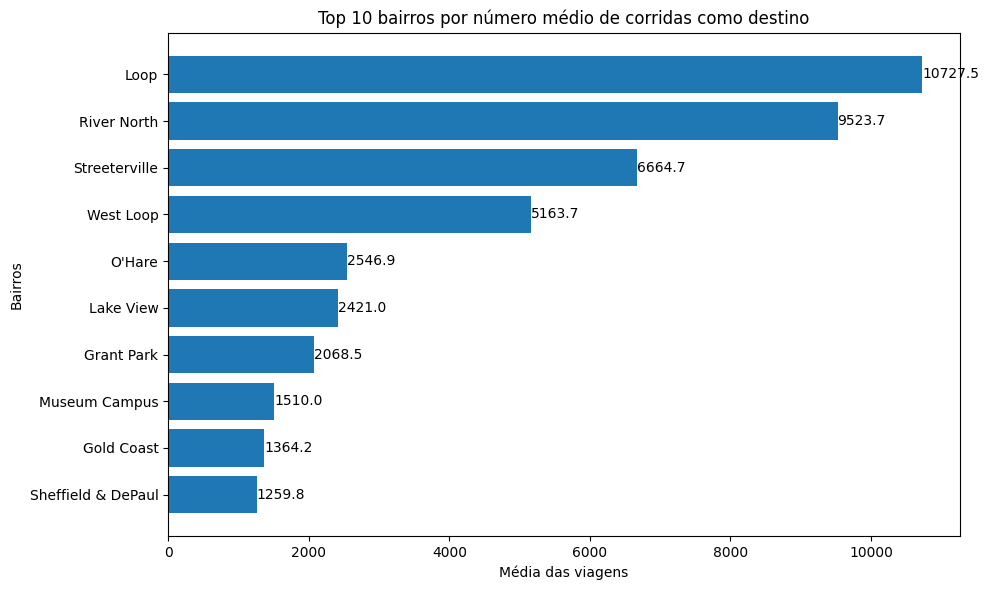

In [ ]:
race_top_10 = dropoff.sort_values(by='average_trips', ascending=False).head(10)

plt.figure(figsize=(10,6))

plt.barh(race_top_10['dropoff_location_name'], race_top_10['average_trips'])
plt.title('Top 10 bairros por número médio de corridas como destino')
plt.xlabel('Média das viagens')
plt.ylabel('Bairros')
plt.gca().invert_yaxis()
for index, value in enumerate(race_top_10['average_trips']):
    plt.text(
        value,
        index,
        f'{value:.1f}',
        va='center'
    )
plt.tight_layout()
plt.show()

#### Conclusão 
A análise do gráfico mostra que as corridas de táxi possuem uma concentração maior em alguns bairros específicos de Chicago. O bairro Loop apresenta a maior média de viagens como destino, seguido por River North e Streeterville, indicando que essas regiões possuem uma demanda elevada de deslocamentos. A diferença significativa entre os primeiros colocados e os demais bairros evidencia que alguns locais funcionam como importantes pontos de atração de passageiros, provavelmente por concentrarem áreas comerciais, turísticas e de grande circulação de pessoas.

# Testando hipóteses

In [ ]:
hypothesis_test = pd.read_csv('data/project_sql_result_07.csv')
hypothesis_test.head(10)

,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0
5,2017-11-11 04:00:00,Good,1320.0
6,2017-11-04 16:00:00,Bad,2969.0
7,2017-11-18 11:00:00,Good,2280.0
8,2017-11-11 14:00:00,Good,2460.0
9,2017-11-11 12:00:00,Good,2040.0


#### Imprimindo as informações gerais

In [ ]:
hypothesis_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), object(2)
memory usage: 25.2+ KB


#### Imprimindo as estatísticas descritivas

In [ ]:
hypothesis_test.describe()

,duration_seconds
count,1068.000000
mean,2071.731273
std,769.461125
min,0.000000
25%,1438.250000
50%,1980.000000
75%,2580.000000
max,7440.000000


#### Verificando se existe valores duplicados

In [ ]:
hypothesis_test.duplicated().sum()

197

#### Removendo as linhas duplicadas

In [ ]:
hypothesis_test = hypothesis_test.drop_duplicates()

#### Verficando novamente as linhas duplicadas 

In [ ]:
hypothesis_test.duplicated().sum()

0

#### Verificando quantas opções existem em weather_conditions	

In [ ]:
print(hypothesis_test['weather_conditions'].unique())


['Good' 'Bad']


#### Realizando o teste

H₀: a duração média das corridas do Loop para o Aeroporto O'Hare não muda nos sábados chuvosos.
H₁: a duração média das corridas do Loop para o Aeroporto O'Hare muda nos sábados chuvosos.

In [ ]:
rain = hypothesis_test[hypothesis_test['weather_conditions'] == 'Bad'] 
good = hypothesis_test[hypothesis_test['weather_conditions'] == 'Good']

alpha = 0.05

results = st.ttest_ind(rain['duration_seconds'], good['duration_seconds'], equal_var=False)
print('Valor p', results.pvalue)
if results.pvalue < alpha:
    print('Rejeitamos a hipótese nula')
else:
    print('Não podemos rejeitar a hipótese nula')

Valor p 9.126383933880083e-08
Rejeitamos a hipótese nula


In [ ]:
rain_mean = rain['duration_seconds'].mean()
good_mean  = good['duration_seconds'].mean()

print(f'A média para o clima ruim é {rain_mean:.2f} segundos.\nA média para o clima bom é {good_mean:.2f} segundos')

A média para o clima ruim é 2409.23 segundos.
A média para o clima bom é 2032.25 segundos


Foi utilizado o teste t para duas amostras independentes (scipy.stats.ttest_ind), pois o objetivo é comparar a média da duração das viagens entre dois grupos independentes:

viagens realizadas com clima "Bad" (chuva ou tempestade),
viagens realizadas com clima "Good" (demais condições climáticas).

Foi usado um nível de relevancia de 0,05. Se o valor-p obtido no teste for menor que 0,05, rejeitamos a hipótese nula. A duração média das corridas em clima ruim foi de 2409.23 segundos, enquanto em clima bom foi de 2032.25 segundos. Isso indica que as viagens tendem a durar mais quando chove, possivelmente devido ao trânsito mais lento e à menor visibilidade.

## Conclusão do projeto

Neste projeto, utilizei SQL e Python para analisar dados de corridas de táxi em Chicago. A análise mostrou que a Flash Cab foi a empresa com o maior número de corridas e que o Loop foi o bairro com a maior média de destinos. Além disso, o teste de hipótese apresentou um valor-p de aproximadamente 6,74e12, permitindo rejeitar a hipótese nula e concluir que as viagens entre o Loop e o Aeroporto O'Hare tendem a ser mais longas em sábados com clima ruim. Esses resultados mostram como a análise de dados pode ajudar a entender padrões e apoiar a tomada de decisões.